<a href="https://colab.research.google.com/github/noorrami/ptbxl-ecg-classification/blob/main/notebooks/01_data_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PTB-XL ECG Classification

## Notebook 01 — Dataset Audit and Integrity Verification

**Course:** ECOM 6306 — Supervised Machine Learning  
**Dataset:** PTB-XL v1.0.3 — PhysioNet  
**Environment:** Google Colab

### Objective

Examine the PTB-XL dataset structure, diagnostic annotations, patient identifiers, official data partitions, and ECG waveform integrity before defining the supervised learning task.

**Scope:** Metadata validation, label analysis, patient-level leakage checks, and preliminary ECG visualization.

**Output:** Reproducible dataset audit reports and an evidence-based foundation for subsequent preprocessing and model development.

Phase 0: Dependency Installation

In [2]:
%pip install -q wfdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 5.1 MB/s eta 0:00:00


In [3]:
import wfdb

print("WFDB Version:", wfdb.__version__)
print("WFDB successfully imported.")

WFDB Version: 4.3.1
WFDB successfully imported.


Phase 1: Environment Initialization

In [4]:
from pathlib import Path
import ast
import json
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

from google.colab import drive

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/ML_Master_Project")
RAW = ROOT / "data" / "raw" / "ptb-xl"
RESULTS = ROOT / "results" / "dataset_audit"

RAW.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)

BASE_URL = "https://physionet.org/files/ptb-xl/1.0.3"

print("Dataset directory:", RAW)
print("Audit directory:", RESULTS)

Mounted at /content/drive
Dataset directory: /content/drive/MyDrive/ML_Master_Project/data/raw/ptb-xl
Audit directory: /content/drive/MyDrive/ML_Master_Project/results/dataset_audit


Phase 2: Official Metadata Acquisition

In [5]:
metadata_files = [
    "ptbxl_database.csv",
    "scp_statements.csv"
]

for filename in metadata_files:
    destination = RAW / filename

    if not destination.exists():
        urllib.request.urlretrieve(
            f"{BASE_URL}/{filename}",
            destination
        )

    print(filename, "—", destination.stat().st_size, "bytes")

ptbxl_database.csv — 6594879 bytes
scp_statements.csv — 9720 bytes


Phase 3: Metadata Loading

In [6]:
df = pd.read_csv(
    RAW / "ptbxl_database.csv",
    index_col="ecg_id"
)

scp = pd.read_csv(
    RAW / "scp_statements.csv",
    index_col=0
)

df["scp_codes"] = df["scp_codes"].apply(ast.literal_eval)

print("ECG records:", len(df))
print("Unique patients:", df["patient_id"].nunique())
print("Metadata columns:", len(df.columns))

display(df.head())
display(scp.head())

ECG records: 21799
Unique patients: 18869
Metadata columns: 27


,patient_id,age,sex,height,weight,nurse,site,device,recording_date,report,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
ecg_id,,,,,,,,,,,,,,,,,,,,,
1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,sinusrhythmus periphere niederspannung,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,sinusbradykardie sonst normales ekg,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,sinusrhythmus normales ekg,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,sinusrhythmus normales ekg,...,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,sinusrhythmus normales ekg,...,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr


,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
NDT,non-diagnostic T abnormalities,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,non-diagnostic T abnormalities,NaN,NaN,NaN,NaN
NST_,non-specific ST changes,1.0,1.0,NaN,STTC,NST_,Basic roots for coding ST-T changes and abnorm...,non-specific ST changes,145.0,MDC_ECG_RHY_STHILOST,NaN,NaN
DIG,digitalis-effect,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,suggests digitalis-effect,205.0,NaN,NaN,NaN
LNGQT,long QT-interval,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,long QT-interval,148.0,NaN,NaN,NaN
NORM,normal ECG,1.0,NaN,NaN,NORM,NORM,Normal/abnormal,normal ECG,1.0,NaN,NaN,F-000B7


Phase 4: Dataset Schema Inspection

In [7]:
print("Metadata columns:")
print(df.columns.tolist())

print("\nColumn types:")
display(df.dtypes.to_frame("dtype"))

print("\nDataset dimensions:")
print(df.shape)

print("\nSCP statement dimensions:")
print(scp.shape)

Metadata columns:
['patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'validated_by', 'second_opinion', 'initial_autogenerated_report', 'validated_by_human', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr']

Column types:


,dtype
patient_id,float64
age,float64
sex,int64
height,float64
weight,float64
nurse,float64
site,float64
device,object
recording_date,object
report,object



Dataset dimensions:
(21799, 27)

SCP statement dimensions:
(71, 12)


Phase 5: Missing Values and Duplicate Records

In [8]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100
}).sort_values("missing_percent", ascending=False)

print("Duplicate ECG IDs:", df.index.duplicated().sum())
print("Missing patient IDs:", df["patient_id"].isna().sum())
print("Missing fold IDs:", df["strat_fold"].isna().sum())

display(missing.head(20))

Duplicate ECG IDs: 0
Missing patient IDs: 0
Missing fold IDs: 0


,missing_count,missing_percent
electrodes_problems,21769,99.862379
infarction_stadium2,21696,99.527501
pacemaker,21508,98.665076
burst_noise,21186,97.187944
baseline_drift,20201,92.669389
extra_beats,19850,91.059223
static_noise,18539,85.045186
infarction_stadium1,16187,74.255700
height,14825,68.007707
weight,12378,56.782421


Phase 6: Diagnostic Label Extraction

In [9]:
diagnostic_map = scp.loc[
    scp["diagnostic"] == 1,
    "diagnostic_class"
].dropna().to_dict()

def extract_diagnostic_classes(code_dict):
    return sorted({
        diagnostic_map[code]
        for code in code_dict
        if code in diagnostic_map
    })

df["diagnostic_classes"] = df["scp_codes"].apply(
    extract_diagnostic_classes
)

df["n_diagnostic_classes"] = df[
    "diagnostic_classes"
].apply(len)

display(
    df[[
        "patient_id",
        "strat_fold",
        "scp_codes",
        "diagnostic_classes"
    ]].head(10)
)

,patient_id,strat_fold,scp_codes,diagnostic_classes
ecg_id,,,,
1,15709.0,3,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",[NORM]
2,13243.0,2,"{'NORM': 80.0, 'SBRAD': 0.0}",[NORM]
3,20372.0,5,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
4,17014.0,3,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
5,17448.0,4,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
6,19005.0,4,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
7,16193.0,7,"{'NORM': 100.0, 'SR': 0.0}",[NORM]
8,11275.0,9,"{'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}",[MI]
9,18792.0,10,"{'NORM': 100.0, 'SR': 0.0}",[NORM]


Phase 7: Diagnostic Class Distribution

,record_count
NORM,9514
MI,5469
STTC,5235
CD,4898
HYP,2649


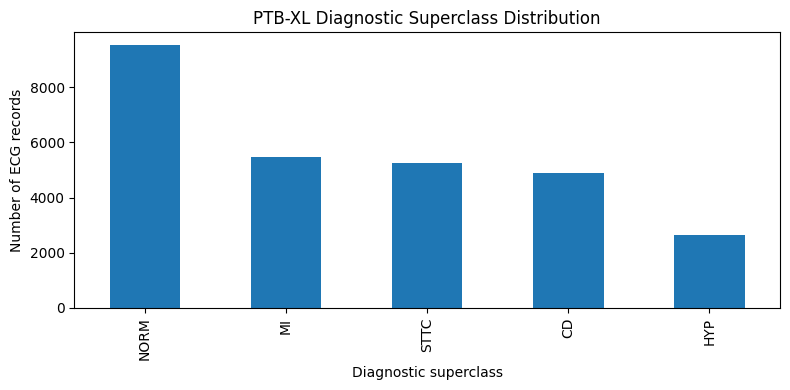

In [10]:
from collections import Counter

class_counts = Counter(
    label
    for labels in df["diagnostic_classes"]
    for label in labels
)

class_distribution = (
    pd.Series(class_counts, name="record_count")
    .sort_values(ascending=False)
)

display(class_distribution.to_frame())

class_distribution.plot(
    kind="bar",
    figsize=(8, 4),
    title="PTB-XL Diagnostic Superclass Distribution"
)

plt.xlabel("Diagnostic superclass")
plt.ylabel("Number of ECG records")
plt.tight_layout()
plt.show()

Phase 8: NORM vs MI Label Eligibility Audit

In [11]:
df["has_norm"] = df["diagnostic_classes"].apply(
    lambda labels: "NORM" in labels
)

df["has_mi"] = df["diagnostic_classes"].apply(
    lambda labels: "MI" in labels
)

norm_only = df["has_norm"] & ~df["has_mi"]
mi_only = df["has_mi"] & ~df["has_norm"]
both = df["has_norm"] & df["has_mi"]

print("NORM without MI:", norm_only.sum())
print("MI without NORM:", mi_only.sum())
print("Both NORM and MI:", both.sum())

print(
    "Other diagnostic classes among NORM/MI candidates:",
    (
        df.loc[norm_only | mi_only, "n_diagnostic_classes"] > 1
    ).sum()
)

NORM without MI: 9513
MI without NORM: 5468
Both NORM and MI: 1
Other diagnostic classes among NORM/MI candidates: 3380


Phase 9: Official Fold Distribution

In [12]:
fold_summary = (
    df.groupby("strat_fold")
    .agg(
        records=("patient_id", "size"),
        patients=("patient_id", "nunique")
    )
    .sort_index()
)

display(fold_summary)

print("Fold identifiers:", sorted(df["strat_fold"].unique()))

,records,patients
strat_fold,,
1,2175,1878
2,2181,1849
3,2192,1887
4,2174,1883
5,2174,1890
6,2173,1884
7,2176,1871
8,2173,1881
9,2183,1942


Fold identifiers: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


Phase 10: Patient-Level Leakage Verification

In [13]:
patient_fold_counts = (
    df.groupby("patient_id")["strat_fold"]
    .nunique()
)

overlapping_patients = patient_fold_counts[
    patient_fold_counts > 1
]

print(
    "Patients assigned to multiple folds:",
    len(overlapping_patients)
)

if len(overlapping_patients) == 0:
    print("PASS: No patient overlap across folds.")
else:
    print("WARNING: Patient overlap detected.")
    display(overlapping_patients.head(20))

Patients assigned to multiple folds: 0
PASS: No patient overlap across folds.


Phase 11: ECG Waveform Acquisition

In [14]:
sample_id = df.index[0]
record_path = df.loc[sample_id, "filename_lr"]

for extension in [".hea", ".dat"]:
    relative_path = record_path + extension
    destination = RAW / relative_path

    destination.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    if not destination.exists():
        urllib.request.urlretrieve(
            f"{BASE_URL}/{relative_path}",
            destination
        )

record = wfdb.rdrecord(
    str(RAW / record_path)
)

print("ECG ID:", sample_id)
print("Sampling frequency:", record.fs, "Hz")
print("Signal shape:", record.p_signal.shape)
print("Lead names:", record.sig_name)
print("Duration:", record.sig_len / record.fs, "seconds")

ECG ID: 1
Sampling frequency: 100 Hz
Signal shape: (1000, 12)
Lead names: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
Duration: 10.0 seconds


Phase 12: Twelve-Lead ECG Visualization

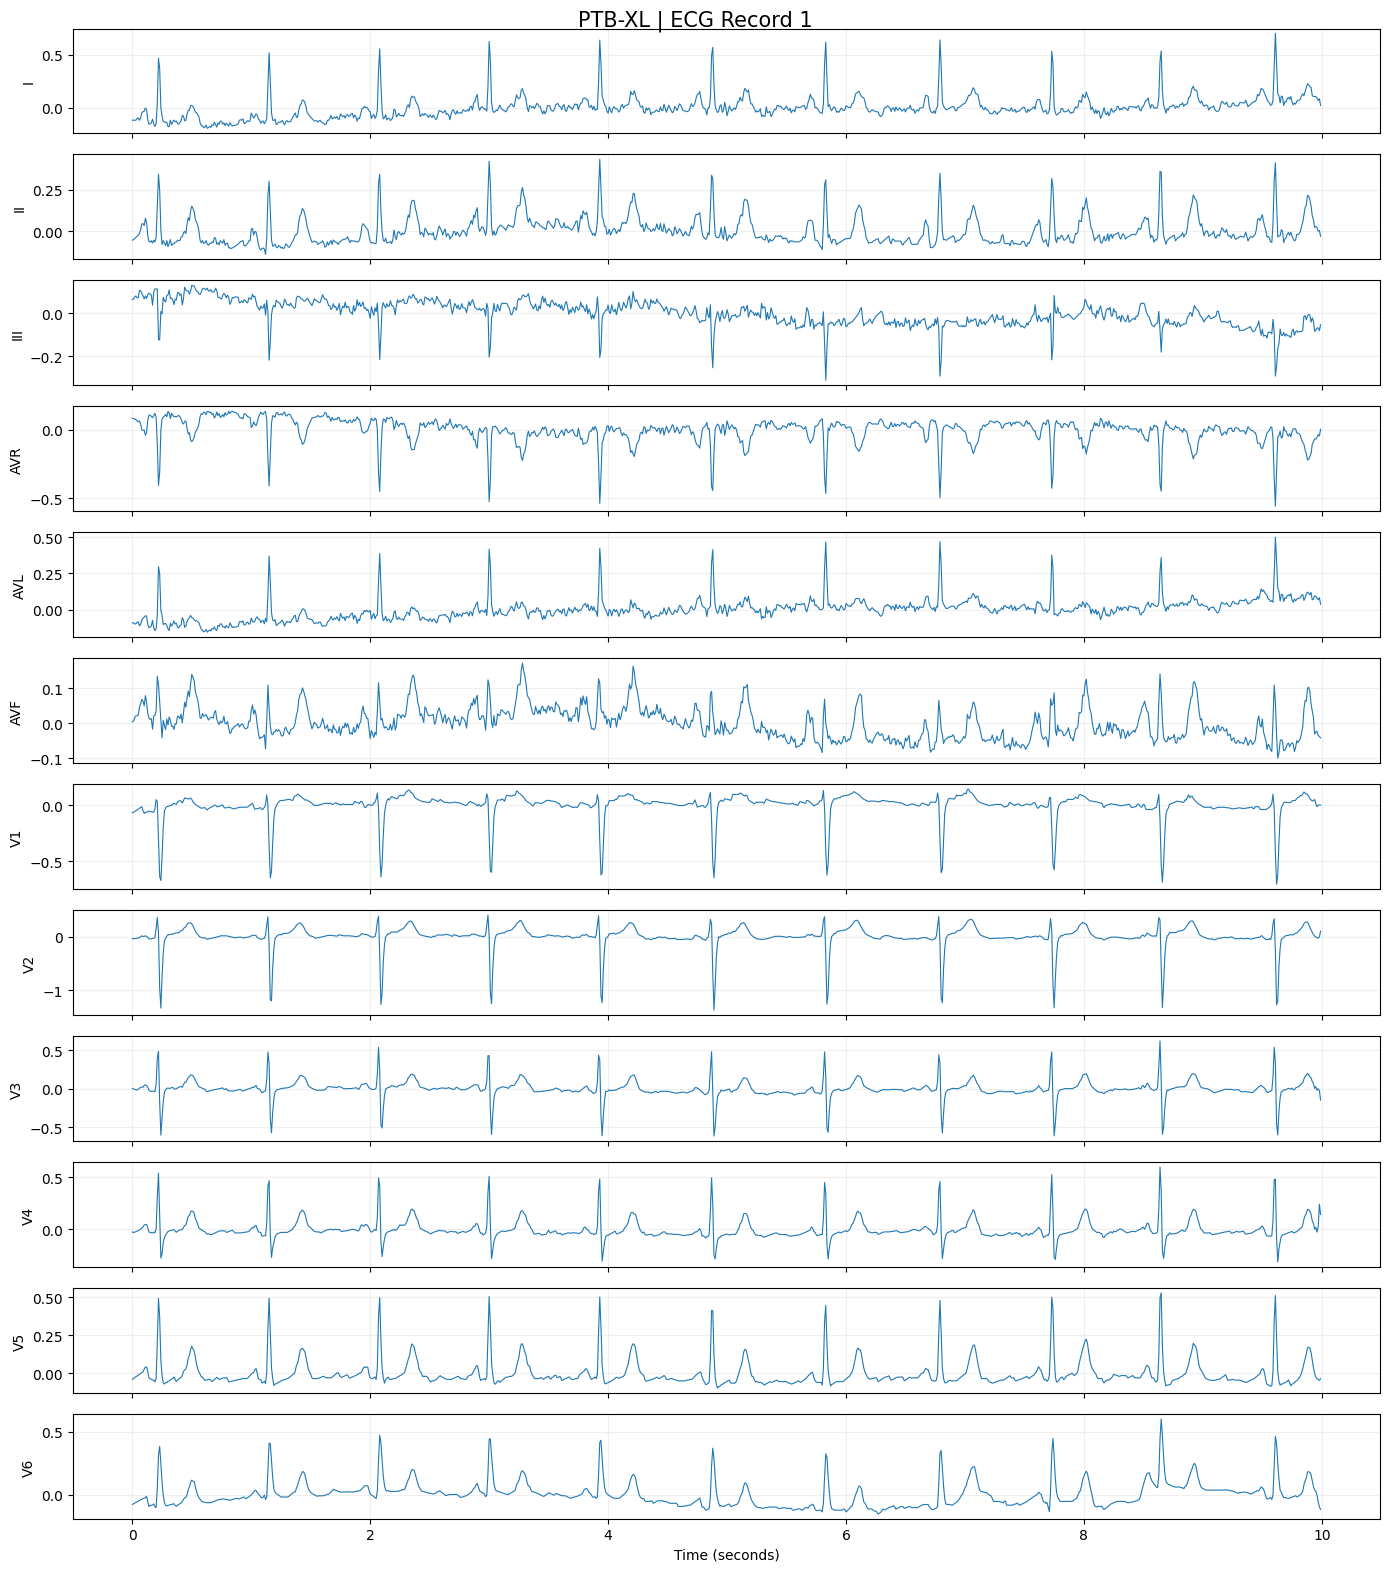

In [15]:
signal = record.p_signal
time = np.arange(signal.shape[0]) / record.fs

fig, axes = plt.subplots(
    12, 1,
    figsize=(14, 16),
    sharex=True
)

for i, ax in enumerate(axes):
    ax.plot(time, signal[:, i], linewidth=0.8)
    ax.set_ylabel(record.sig_name[i])
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Time (seconds)")

fig.suptitle(
    f"PTB-XL | ECG Record {sample_id}",
    fontsize=15
)

plt.tight_layout()
plt.savefig(
    RESULTS / "sample_12lead_ecg.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

Phase 13: Dataset Audit Report Export

In [16]:
audit_report = {
    "dataset": "PTB-XL",
    "version": "1.0.3",
    "total_records": int(len(df)),
    "unique_patients": int(df["patient_id"].nunique()),
    "duplicate_ecg_ids": int(df.index.duplicated().sum()),
    "missing_patient_ids": int(df["patient_id"].isna().sum()),
    "patients_in_multiple_folds": int(
        len(overlapping_patients)
    ),
    "norm_without_mi": int(norm_only.sum()),
    "mi_without_norm": int(mi_only.sum()),
    "norm_and_mi": int(both.sum()),
    "diagnostic_class_counts": {
        str(k): int(v)
        for k, v in class_counts.items()
    },
    "sample_ecg_id": int(sample_id),
    "sample_sampling_frequency": float(record.fs),
    "sample_signal_shape": list(signal.shape)
}

report_path = RESULTS / "dataset_audit.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(audit_report, f, indent=4)

print("Audit report saved:", report_path)

Audit report saved: /content/drive/MyDrive/ML_Master_Project/results/dataset_audit/dataset_audit.json


Phase 14: Strict Binary Cohort Definition

In [17]:
strict_norm = df["diagnostic_classes"].apply(
    lambda labels: labels == ["NORM"]
)

strict_mi = df["diagnostic_classes"].apply(
    lambda labels: labels == ["MI"]
)

strict_cohort = df.loc[
    strict_norm | strict_mi
].copy()

strict_cohort["target"] = np.where(
    strict_norm.loc[strict_cohort.index],
    0,
    1
)

print("Strict cohort records:", len(strict_cohort))
print("Unique patients:", strict_cohort["patient_id"].nunique())

display(
    strict_cohort["target"]
    .value_counts()
    .rename(index={0: "NORM", 1: "MI"})
    .to_frame("records")
)

Strict cohort records: 11601
Unique patients: 10652


,records
target,
NORM,9069
MI,2532


Phase 15: Class Distribution Across Official Folds

In [18]:
fold_class_counts = pd.crosstab(
    strict_cohort["strat_fold"],
    strict_cohort["target"]
)

fold_class_counts = fold_class_counts.rename(
    columns={0: "NORM", 1: "MI"}
)

fold_class_counts["total"] = (
    fold_class_counts["NORM"]
    + fold_class_counts["MI"]
)

display(fold_class_counts)

target,NORM,MI,total
strat_fold,,,
1,898,262,1160
2,925,253,1178
3,941,229,1170
4,885,269,1154
5,893,248,1141
6,890,261,1151
7,922,255,1177
8,889,266,1155
9,914,233,1147


Phase 16: Patient-Level Target Consistency Audit

In [19]:
patient_target_counts = (
    strict_cohort.groupby("patient_id")["target"]
    .nunique()
)

mixed_target_patients = patient_target_counts[
    patient_target_counts > 1
]

print(
    "Patients with both target classes:",
    len(mixed_target_patients)
)

print(
    "Patients with a single target class:",
    (patient_target_counts == 1).sum()
)

print(
    "Patient overlap across folds:",
    (
        strict_cohort.groupby("patient_id")["strat_fold"]
        .nunique() > 1
    ).sum()
)

Patients with both target classes: 85
Patients with a single target class: 10567
Patient overlap across folds: 0


Phase 17: Final Cohort Validation and Export

In [20]:
# Validate binary labels
assert set(strict_cohort["target"].unique()) == {0, 1}

# Validate mutually exclusive diagnostic classes
assert strict_cohort["diagnostic_classes"].apply(
    lambda x: x in (["NORM"], ["MI"])
).all()

# Validate patient-level fold isolation
assert (
    strict_cohort.groupby("patient_id")["strat_fold"]
    .nunique()
    .max()
    == 1
)

# Validate official fold assignments
assert strict_cohort["strat_fold"].between(1, 10).all()

# Preserve diagnostic labels in a portable format
cohort_export = strict_cohort.copy()

cohort_export["diagnostic_classes"] = (
    cohort_export["diagnostic_classes"].apply(
        lambda labels: "|".join(labels)
    )
)

cohort_path = RESULTS / "strict_binary_cohort.csv"

cohort_export.to_csv(
    cohort_path,
    index=True
)

print("Cohort saved:", cohort_path)
print("Records:", len(cohort_export))
print("Patients:", cohort_export["patient_id"].nunique())
print("Class distribution:")
print(cohort_export["target"].value_counts().sort_index())

Cohort saved: /content/drive/MyDrive/ML_Master_Project/results/dataset_audit/strict_binary_cohort.csv
Records: 11601
Patients: 10652
Class distribution:
target
0    9069
1    2532
Name: count, dtype: int64
